In [1]:
import pandas as pd

## Acesso ao dataset. A coluna Data está no formato Object e precisa ser transformada para Datetime.

In [2]:
dados = '/home/ubuntu/Cursos/Alura/Prophet/dados/poluentes.csv'
df = pd.read_csv(dados)
df.head()

,Data,PM2.5,PM10,SO2,NO2,CO,O3,TEMP
0,2020-03-01,7.0,11.0,12.0,23.0,429.0,64.0,1.0
1,2020-03-02,31.0,42.0,37.0,67.0,825.0,30.0,1.0
2,2020-03-03,77.0,121.0,61.0,81.0,1621.0,19.0,6.0
3,2020-03-04,23.0,45.0,23.0,46.0,606.0,54.0,10.0
4,2020-03-05,149.0,184.0,94.0,133.0,2358.0,68.0,6.0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Data    1460 non-null   object 
 1   PM2.5   1460 non-null   float64
 2   PM10    1460 non-null   float64
 3   SO2     1460 non-null   float64
 4   NO2     1460 non-null   float64
 5   CO      1460 non-null   float64
 6   O3      1460 non-null   float64
 7   TEMP    1460 non-null   float64
dtypes: float64(7), object(1)
memory usage: 91.4+ KB


In [4]:
df['Data'] = pd.to_datetime(df['Data'])

### Agora a coluna Data está no formato correto

### Vamos criar agora um gráfico interativo com os dados

In [5]:
import plotly.express as px

fig = px.line(df, 
              x='Data', 
              y='O3')
fig.show()

### Vamos filtrar por um ano para verificar a sazonalidade

In [6]:
df_2022 = df[df['Data'].dt.year == 2022]
df_2022_mensal = df_2022.groupby(df_2022['Data'].dt.month)['O3'].mean().reset_index()

In [7]:
import calendar 

df_2022_mensal['Mês'] = df_2022_mensal['Data'].apply(lambda x: calendar.month_abbr[x])


In [8]:
fig = px.bar(df_2022_mensal,
             x="Mês",
             y="O3",
             title = "Média mensal de O3 em ug/m3 em 2022")
fig.show()

In [9]:
from prophet import Prophet 

/home/ubuntu/Cursos/Alura/Prophet/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning:

IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html



In [10]:
df_prophet = pd.DataFrame()
df_prophet['ds'] = df['Data']
df_prophet['y'] = df['O3']

In [11]:
df_prophet

,ds,y
0,2020-03-01,64.0
1,2020-03-02,30.0
2,2020-03-03,19.0
3,2020-03-04,54.0
4,2020-03-05,68.0
...,...,...
1455,2024-02-24,51.0
1456,2024-02-25,66.0
1457,2024-02-26,49.0
1458,2024-02-27,37.0


In [12]:
import numpy as np
np.random.seed(4587) #Esse código só é usado para os resultados serem iguais so da professora

In [13]:
modelo = Prophet()
modelo.fit(df_prophet)

futuro = modelo.make_future_dataframe(periods = 365, 
                                      freq = 'D')
previsao = modelo.predict(futuro)

03:16:03 - cmdstanpy - INFO - Chain [1] start processing
03:16:03 - cmdstanpy - INFO - Chain [1] done processing


In [14]:
from prophet.plot import plot_plotly

fig = plot_plotly(modelo, previsao)
fig.show()

In [15]:
previsao

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,weekly,weekly_lower,weekly_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2020-03-01,36.746580,-11.381672,49.916885,36.746580,36.746580,-17.568647,-17.568647,-17.568647,-2.094147,-2.094147,-2.094147,-15.474500,-15.474500,-15.474500,0.0,0.0,0.0,19.177933
1,2020-03-02,36.774403,-6.262445,54.225201,36.774403,36.774403,-13.470362,-13.470362,-13.470362,0.920163,0.920163,0.920163,-14.390526,-14.390526,-14.390526,0.0,0.0,0.0,23.304040
2,2020-03-03,36.802226,-7.160647,56.269547,36.802226,36.802226,-10.626348,-10.626348,-10.626348,2.599477,2.599477,2.599477,-13.225826,-13.225826,-13.225826,0.0,0.0,0.0,26.175877
3,2020-03-04,36.830049,-5.897684,55.560802,36.830049,36.830049,-11.813282,-11.813282,-11.813282,0.188052,0.188052,0.188052,-12.001334,-12.001334,-12.001334,0.0,0.0,0.0,25.016767
4,2020-03-05,36.857871,-3.363930,56.568511,36.857871,36.857871,-10.548997,-10.548997,-10.548997,0.190030,0.190030,0.190030,-10.739026,-10.739026,-10.739026,0.0,0.0,0.0,26.308875
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1820,2025-02-23,61.957147,9.393200,68.988411,60.377531,63.357503,-21.514463,-21.514463,-21.514463,-2.094147,-2.094147,-2.094147,-19.420316,-19.420316,-19.420316,0.0,0.0,0.0,40.442684
1821,2025-02-24,61.954497,13.838497,73.606642,60.369400,63.363886,-18.256294,-18.256294,-18.256294,0.920163,0.920163,0.920163,-19.176458,-19.176458,-19.176458,0.0,0.0,0.0,43.698202
1822,2025-02-25,61.951847,16.474458,76.614522,60.361269,63.370170,-16.176144,-16.176144,-16.176144,2.599477,2.599477,2.599477,-18.775622,-18.775622,-18.775622,0.0,0.0,0.0,45.775702
1823,2025-02-26,61.949196,13.131689,73.269177,60.353138,63.372395,-18.033508,-18.033508,-18.033508,0.188052,0.188052,0.188052,-18.221560,-18.221560,-18.221560,0.0,0.0,0.0,43.915688


### yhat é o valor de y previsto
### yhat_lower = intervalo de confiança inferior
### yhat upper = intervalo de confiança superior

In [16]:
previsao[['ds', 'yhat', 'yhat_lower', 'yhat_upper']] 

,ds,yhat,yhat_lower,yhat_upper
0,2020-03-01,19.177933,-11.381672,49.916885
1,2020-03-02,23.304040,-6.262445,54.225201
2,2020-03-03,26.175877,-7.160647,56.269547
3,2020-03-04,25.016767,-5.897684,55.560802
4,2020-03-05,26.308875,-3.363930,56.568511
...,...,...,...,...
1820,2025-02-23,40.442684,9.393200,68.988411
1821,2025-02-24,43.698202,13.838497,73.606642
1822,2025-02-25,45.775702,16.474458,76.614522
1823,2025-02-26,43.915688,13.131689,73.269177


In [17]:
from prophet.plot import plot_components_plotly

plot_components_plotly(modelo, previsao)

## Equação para modelar a série temporal

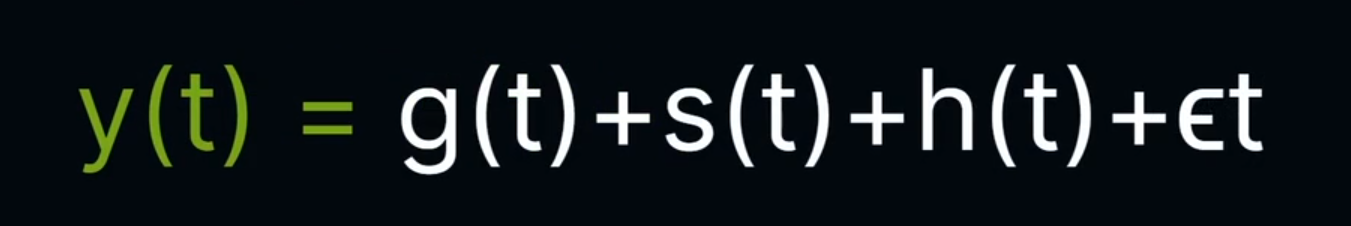

### y(t) = valor observado
### g(t) = componente de tendência
### s(t) = componente sazonal 
### h(t) = componente de efeitos de feriados
### et = erro aleatório

In [18]:
df_prophet.shape

(1460, 2)

### Para medir a precisão do modelo, vamos separar os dados em conjuntos de treino e teste
### Para isso, vamos separar em 80% para treino e 20% para teste

In [19]:
tamanho_treino = int(len(df_prophet) * 0.8)
tamanho_teste = int(len(df_prophet) * 0.2)
print(f'tamanho do treino: {tamanho_treino}')
print(f'tamanho do teste: {tamanho_teste}')


tamanho do treino: 1168
tamanho do teste: 292


### Aqui, nós criamos então os dois DataFrames separados

In [20]:
# df de treino
df_treino = pd.DataFrame()
df_treino['ds'] = df_prophet['ds'][:1168] #Esse padrão de dois pontos entre colchetes significa pegar os dados até 1168
df_treino['y'] = df_prophet['y'][:1168]

In [21]:
df_treino.shape #com o shape nós vemos que o valor bate com o cáçculo

(1168, 2)

In [22]:
# df_teste
df_teste = pd.DataFrame()
df_teste['ds'] = df_prophet['ds'][1168:] #aqui, o padrão de dois pontos significa pegar os dados a partir de 1168
df_teste['y'] = df_prophet['y'][1168:]

In [23]:
df_teste.shape

(292, 2)

In [24]:
np.random.seed(4587)

In [25]:
modelo = Prophet()
modelo.fit(df_treino)
futuro = modelo.make_future_dataframe(periods = 292, #Esse valor corresponde a 80% dos dias de um ano
                                      freq = 'D')
previsao = modelo.predict(futuro)

03:16:04 - cmdstanpy - INFO - Chain [1] start processing
03:16:04 - cmdstanpy - INFO - Chain [1] done processing


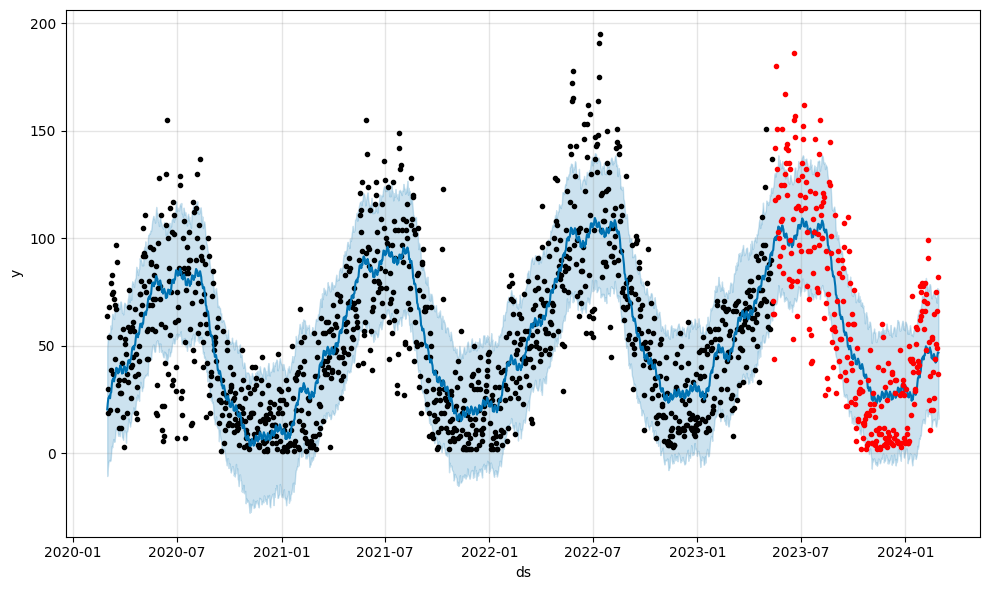

In [26]:
fig1 = modelo.plot(previsao)

import matplotlib.pyplot as plt
plt.plot(df_teste['ds'], df_teste['y'], '.r')

plt.show()

In [27]:
df_previsao = previsao[['ds', 'yhat']]
df_comparacao = pd.merge(df_previsao, df_teste, on='ds', how='inner')
df_comparacao

,ds,yhat,y
0,2023-05-13,94.170276,65.0
1,2023-05-14,94.510860,71.0
2,2023-05-15,97.567865,44.0
3,2023-05-16,99.846036,65.0
4,2023-05-17,100.122114,118.0
...,...,...,...
287,2024-02-24,43.382947,51.0
288,2024-02-25,42.878326,66.0
289,2024-02-26,45.227536,49.0
290,2024-02-27,46.948349,37.0


In [28]:
from sklearn.metrics import mean_squared_error


In [29]:
mse = mean_squared_error(df_comparacao['y'], df_comparacao['yhat'].round(2))
rmse = np.sqrt(mse).round(2)
print(f'MSE: {mse}')
print(f'RMSE: {rmse}')

MSE: 710.0222287671232
RMSE: 26.65


# Remoção de outliers

In [30]:
np.random.seed(4587)

In [31]:
modelo = Prophet()
modelo.fit(df_prophet)
futuro = modelo.make_future_dataframe(periods=0, freq='D') #A IDEIA AQUI É OBTER SÓ O INTERVALO DE CONFIANÇA
previsao = modelo.predict(futuro)

03:16:07 - cmdstanpy - INFO - Chain [1] start processing
03:16:07 - cmdstanpy - INFO - Chain [1] done processing


In [32]:
sem_outliers = df_prophet[(df_prophet['y'] > previsao['yhat_lower']) & (df_prophet['y'] < previsao['yhat_upper'])]

In [33]:
sem_outliers.reset_index(drop=True, inplace=True)

In [34]:
tamanho_treino = int(len(sem_outliers) * 0.8)
tamanho_teste = int(len(sem_outliers) * 0.2)
print(f'tamanho do treino: {tamanho_treino}')
print(f'tamanho do teste: {tamanho_teste}')

tamanho do treino: 960
tamanho do teste: 240


In [35]:
df_treino_sem_outliers = pd.DataFrame()
df_treino_sem_outliers['ds'] = sem_outliers['ds'][:960]
df_treino_sem_outliers['y'] = sem_outliers['y'][:960]
df_treino_sem_outliers.shape

(960, 2)

In [36]:
df_teste_sem_outliers = pd.DataFrame()
df_teste_sem_outliers['ds'] = sem_outliers['ds'][960:]
df_teste_sem_outliers['y'] = sem_outliers['y'][960:]
df_teste_sem_outliers.shape

(241, 2)

In [37]:
np.random.seed(4587) #Esse código só é usado para os resultados serem iguais so da professora

In [38]:
modelo = Prophet()
modelo.fit(df_treino_sem_outliers)
futuro = modelo.make_future_dataframe(periods=365, freq='D')
previsao = modelo.predict(futuro)

03:16:07 - cmdstanpy - INFO - Chain [1] start processing
03:16:07 - cmdstanpy - INFO - Chain [1] done processing


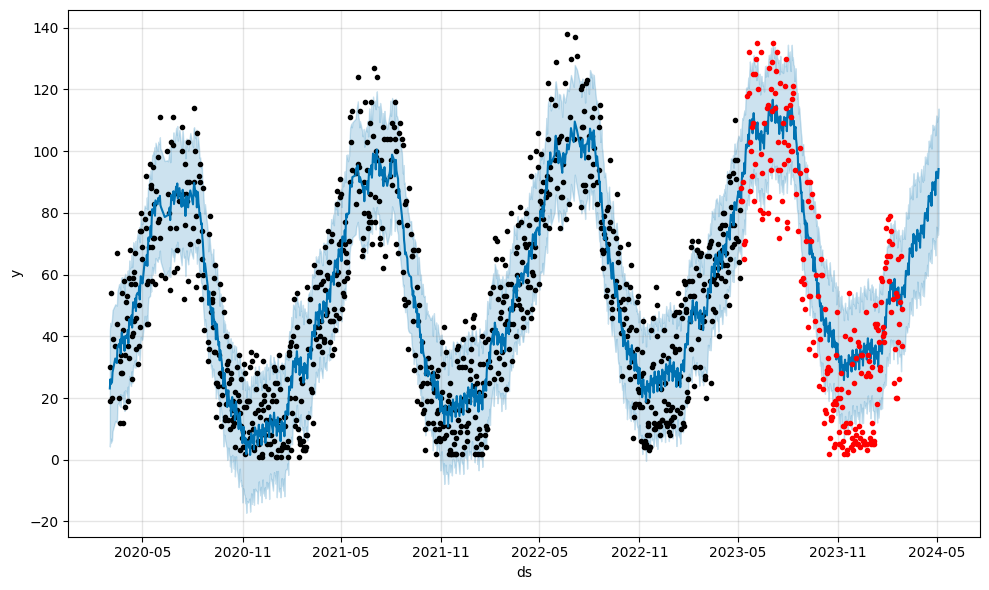

In [39]:
fig1 = modelo.plot(previsao)
plt.plot(df_teste_sem_outliers['ds'], df_teste_sem_outliers['y'], '.r')
plt.show()

In [40]:
df_previsao = previsao[['ds', 'yhat']]
df_comparacao = pd.merge(df_previsao, df_teste_sem_outliers, on='ds', how='inner')
df_comparacao

,ds,yhat,y
0,2023-05-06,88.211252,88.0
1,2023-05-07,84.354934,84.0
2,2023-05-08,89.847203,84.0
3,2023-05-10,91.720998,90.0
4,2023-05-12,92.709438,70.0
...,...,...,...
236,2024-02-22,52.780129,44.0
237,2024-02-24,53.446102,51.0
238,2024-02-25,48.757024,66.0
239,2024-02-26,53.455595,49.0


In [41]:
mse = mean_squared_error(df_comparacao['y'], df_comparacao['yhat'].round(2))
rmse = np.sqrt(mse).round(2)
print(f'MSE: {mse}')
print(f'RMSE: {rmse}')

MSE: 383.6467203319502
RMSE: 19.59


# É possível também alterarmos parâmentros ao instanciar o modelo para fazer ajustes finos e tentar obter um erro menor

03:16:08 - cmdstanpy - INFO - Chain [1] start processing


03:16:08 - cmdstanpy - INFO - Chain [1] done processing


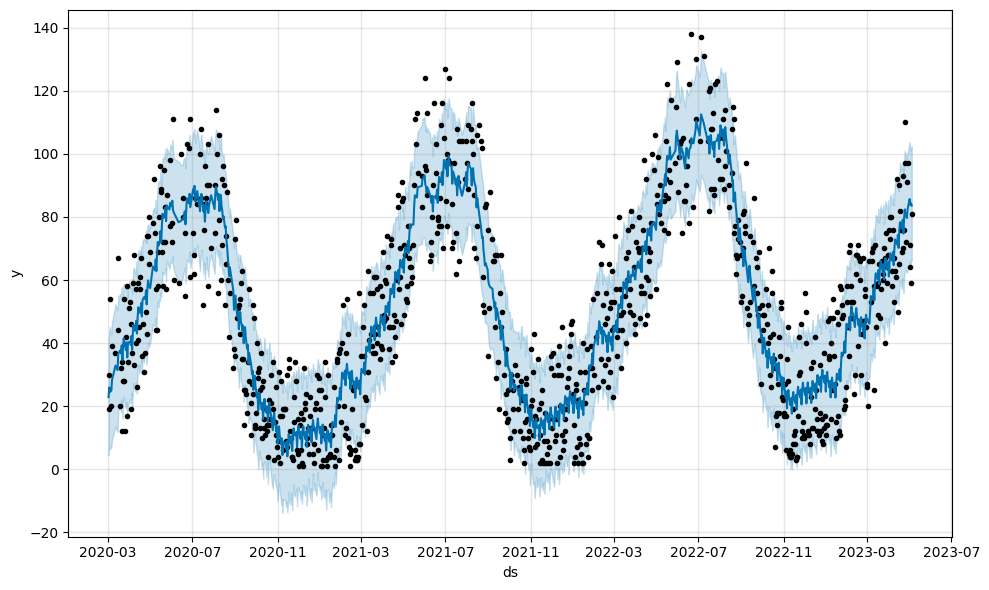

In [42]:
modelo = Prophet(changepoint_prior_scale=0.5) #padrão é 0.05
modelo.fit(df_treino_sem_outliers)
futuro = modelo.make_future_dataframe(periods=0, freq='D')
previsao = modelo.predict(futuro)
fig = modelo.plot(previsao)

In [43]:
fig = plot_components_plotly(modelo, previsao)
fig.show()

03:16:09 - cmdstanpy - INFO - Chain [1] start processing
03:16:09 - cmdstanpy - INFO - Chain [1] done processing


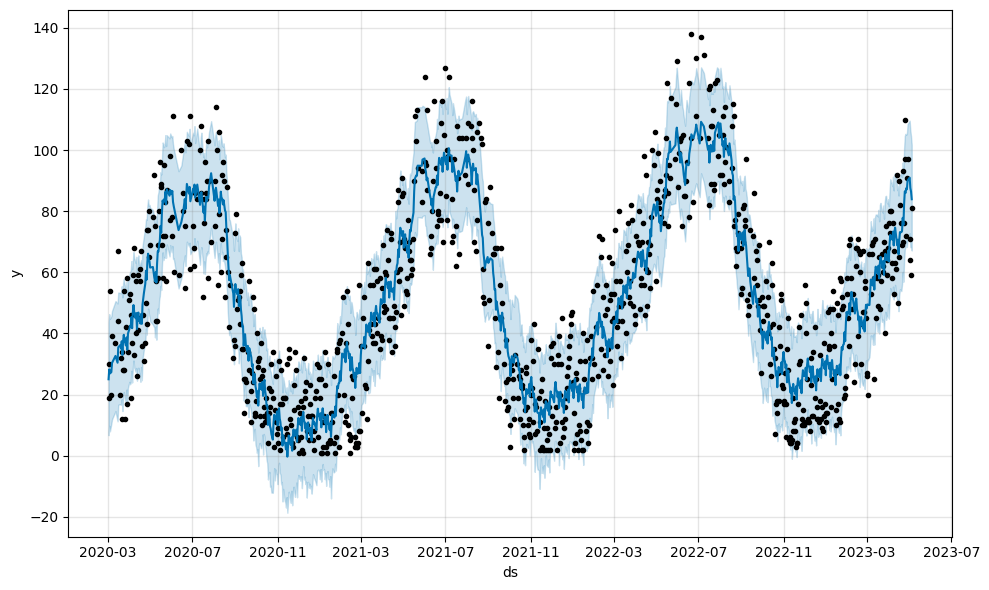

In [44]:
modelo = Prophet(yearly_seasonality=20) #padrão é 10
modelo.fit(df_treino_sem_outliers)
futuro = modelo.make_future_dataframe(periods=0, freq='D')
previsao = modelo.predict(futuro)
fig = modelo.plot(previsao)

In [45]:
fig = plot_components_plotly(modelo, previsao)
fig.show()

Extra: Busca grid de melhores combinações de parâmetros
Em sua documentação, o Prophet traz um exemplo de como realizar a busca por melhores combinações de hiperparâmetros através de uma busca grid. O exemplo de código foi traduzido e está disponível abaixo:

```python
import itertools
import numpy as np
import pandas as pd

param_grid = {  
    'changepoint_prior_scale': [0.001, 0.01, 0.1, 0.5],
    'seasonality_prior_scale': [0.01, 0.1, 1.0, 10.0],
}

# Gerar todas as combinações de parâmetros
all_params = [dict(zip(param_grid.keys(), v)) for v in itertools.product(*param_grid.values())]
rmses = []  # Armazenar os RMSEs para cada conjunto de parâmetros aqui

# Usar validação cruzada para avaliar todos os parâmetros
for params in all_params:
    m = Prophet(**params).fit(df)  # Ajustar o modelo com os parâmetros fornecidos
    df_cv = cross_validation(m, cutoffs=cutoffs, horizon='30 days', parallel="processes")
    df_p = performance_metrics(df_cv, rolling_window=1)
    rmses.append(df_p['rmse'].values[0])

# Encontrar os melhores parâmetros
tuning_results = pd.DataFrame(all_params)
tuning_results['rmse'] = rmses
print(tuning_results)

best_params = all_params[np.argmin(rmses)]
print(best_params)
```


O código começa importando as bibliotecas necessárias e definindo uma grade de parâmetros (param_grid) para ajuste de hiperparâmetros. Ele gera todas as combinações possíveis desses parâmetros utilizando itertools.product. Em seguida, cria uma lista para armazenar os valores de RMSE para cada combinação de parâmetros. Utiliza validação cruzada para avaliar cada combinação de parâmetros, ajustando o modelo Prophet a cada vez e calculando as métricas de desempenho, especificamente o RMSE, que são armazenadas na lista.

In [46]:
modelo_final = Prophet(changepoint_prior_scale=0.5,
                       yearly_seasonality=20)
modelo_final.fit(df_treino_sem_outliers)
futuro = modelo_final.make_future_dataframe(periods=365, freq='D')
previsao = modelo_final.predict(futuro)

03:16:09 - cmdstanpy - INFO - Chain [1] start processing
03:16:09 - cmdstanpy - INFO - Chain [1] done processing


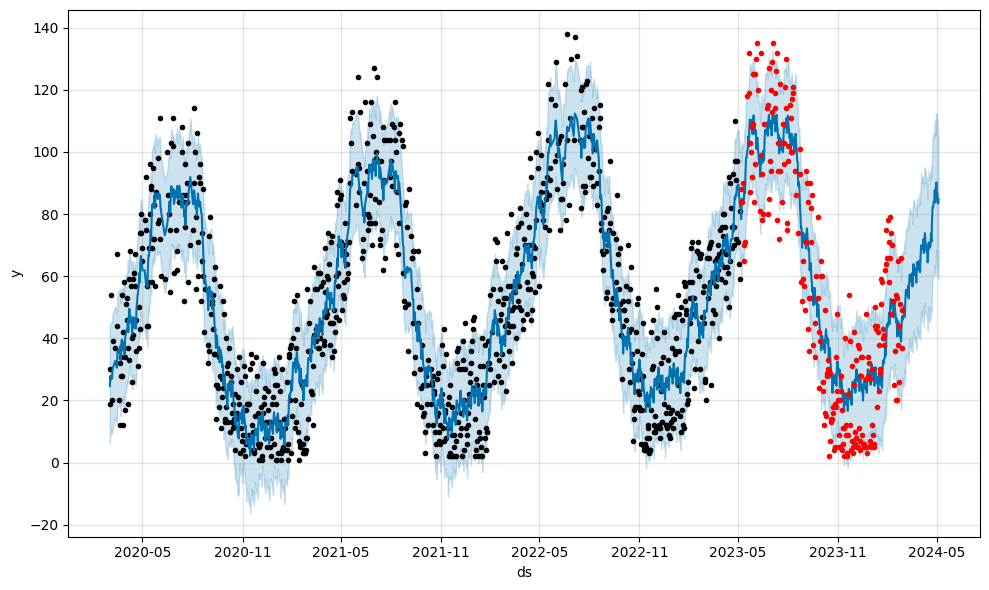

In [47]:
fig1 = modelo_final.plot(previsao)

plt.plot(df_teste_sem_outliers['ds'], df_teste_sem_outliers['y'], '.r')

plt.show()

In [48]:
df_previsao = previsao[['ds', 'yhat']]
df_comparacao = pd.merge(df_previsao, df_teste_sem_outliers, on='ds', how='inner')
df_comparacao

,ds,yhat,y
0,2023-05-06,83.698994,88.0
1,2023-05-07,78.375970,84.0
2,2023-05-08,82.697155,84.0
3,2023-05-10,83.333858,90.0
4,2023-05-12,84.639452,70.0
...,...,...,...
236,2024-02-22,42.049695,44.0
237,2024-02-24,43.079435,51.0
238,2024-02-25,38.903509,66.0
239,2024-02-26,44.212195,49.0


In [49]:
mse = mean_squared_error(df_comparacao['y'], df_comparacao['yhat'].round(2))
rmse = np.sqrt(mse).round(2)
print(f'RMSE: {rmse}')

RMSE: 17.4


In [50]:
from prophet.diagnostics import cross_validation


In [51]:
df_cv = cross_validation(modelo_final, 
                         initial='365.25 days',
                         period='45 days',
                         horizon='90 days') #deveser o dobro do period

  0%|          | 0/16 [00:00<?, ?it/s]

03:16:10 - cmdstanpy - INFO - Chain [1] start processing
03:16:10 - cmdstanpy - INFO - Chain [1] done processing
  6%|▋         | 1/16 [00:00<00:01,  8.77it/s]03:16:10 - cmdstanpy - INFO - Chain [1] start processing
03:16:10 - cmdstanpy - INFO - Chain [1] done processing
 12%|█▎        | 2/16 [00:00<00:01,  8.03it/s]03:16:10 - cmdstanpy - INFO - Chain [1] start processing
03:16:10 - cmdstanpy - INFO - Chain [1] done processing
 19%|█▉        | 3/16 [00:00<00:01,  7.76it/s]03:16:10 - cmdstanpy - INFO - Chain [1] start processing
03:16:10 - cmdstanpy - INFO - Chain [1] done processing
 25%|██▌       | 4/16 [00:00<00:01,  7.57it/s]03:16:11 - cmdstanpy - INFO - Chain [1] start processing
03:16:11 - cmdstanpy - INFO - Chain [1] done processing
 31%|███▏      | 5/16 [00:00<00:01,  7.70it/s]03:16:11 - cmdstanpy - INFO - Chain [1] start processing
03:16:11 - cmdstanpy - INFO - Chain [1] done processing
 38%|███▊      | 6/16 [00:00<00:01,  7.30it/s]03:16:11 - cmdstanpy - INFO - Chain [1] start 

In [52]:
df_cv.head()

,ds,yhat,yhat_lower,yhat_upper,y,cutoff
0,2021-04-01,46.873510,30.469252,63.607147,55.0,2021-03-31
1,2021-04-02,45.310710,28.227762,60.247971,69.0,2021-03-31
2,2021-04-03,47.312864,30.066589,64.216794,49.0,2021-03-31
3,2021-04-04,44.905453,27.699377,61.008105,47.0,2021-03-31
4,2021-04-05,53.586264,36.628166,70.804107,60.0,2021-03-31


In [53]:
df_cv['cutoff'].unique()

<DatetimeArray>
['2021-03-31 00:00:00', '2021-05-15 00:00:00', '2021-06-29 00:00:00',
 '2021-08-13 00:00:00', '2021-09-27 00:00:00', '2021-11-11 00:00:00',
 '2021-12-26 00:00:00', '2022-02-09 00:00:00', '2022-03-26 00:00:00',
 '2022-05-10 00:00:00', '2022-06-24 00:00:00', '2022-08-08 00:00:00',
 '2022-09-22 00:00:00', '2022-11-06 00:00:00', '2022-12-21 00:00:00',
 '2023-02-04 00:00:00']
Length: 16, dtype: datetime64[ns]

In [54]:
from prophet.diagnostics import performance_metrics

In [55]:
df_p = performance_metrics(df_cv)

In [56]:
df_p

,horizon,mse,rmse,mae,mape,mdape,smape,coverage
0,10 days,350.871177,18.731556,15.472480,1.123014,0.290178,0.466000,0.558442
1,11 days,346.216475,18.606893,15.410929,1.148967,0.281382,0.478206,0.542857
2,12 days,335.964779,18.329342,15.464563,1.215998,0.281382,0.493104,0.542857
3,13 days,352.025340,18.762338,15.826145,1.236934,0.299280,0.503540,0.550420
4,14 days,362.245162,19.032739,16.268485,1.230976,0.353988,0.518298,0.551020
...,...,...,...,...,...,...,...,...
76,86 days,302.113374,17.381409,15.164001,0.518419,0.283363,0.362472,0.604278
77,87 days,275.911620,16.610588,14.426486,0.412437,0.254979,0.326593,0.640336
78,88 days,289.981854,17.028854,14.966260,0.456871,0.262682,0.343133,0.621849
79,89 days,302.510284,17.392823,15.116733,0.492161,0.276016,0.356939,0.610860


In [57]:
df_p['rmse'].mean().round(2)

np.float64(17.99)

In [58]:
df_p['mae'].mean().round(2)

np.float64(15.02)

In [59]:
from prophet.plot import plot_cross_validation_metric

/home/ubuntu/Cursos/Alura/Prophet/.venv/lib/python3.12/site-packages/prophet/plot.py:547: FutureWarning:

Series.view is deprecated and will be removed in a future version. Use ``astype`` as an alternative to change the dtype.

/home/ubuntu/Cursos/Alura/Prophet/.venv/lib/python3.12/site-packages/prophet/plot.py:548: FutureWarning:

Series.view is deprecated and will be removed in a future version. Use ``astype`` as an alternative to change the dtype.



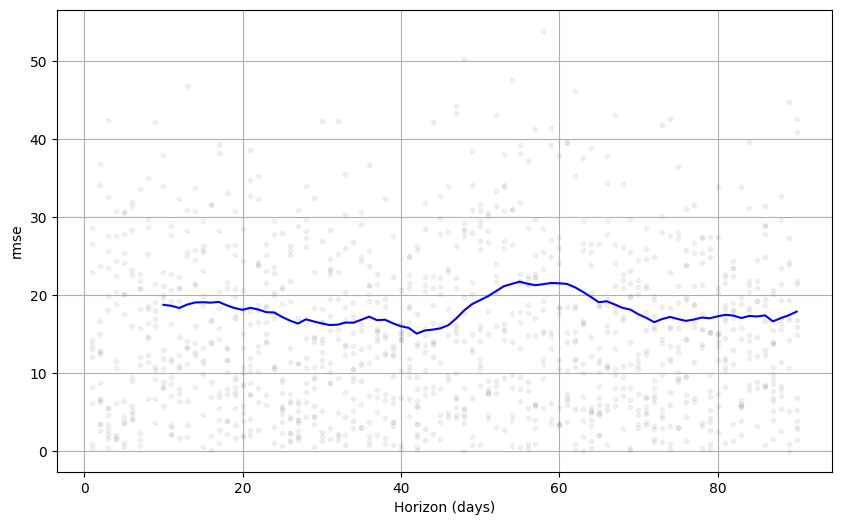

In [60]:
plot_cross_validation_metric(df_cv, metric='rmse');

/home/ubuntu/Cursos/Alura/Prophet/.venv/lib/python3.12/site-packages/prophet/plot.py:547: FutureWarning:

Series.view is deprecated and will be removed in a future version. Use ``astype`` as an alternative to change the dtype.

/home/ubuntu/Cursos/Alura/Prophet/.venv/lib/python3.12/site-packages/prophet/plot.py:548: FutureWarning:

Series.view is deprecated and will be removed in a future version. Use ``astype`` as an alternative to change the dtype.



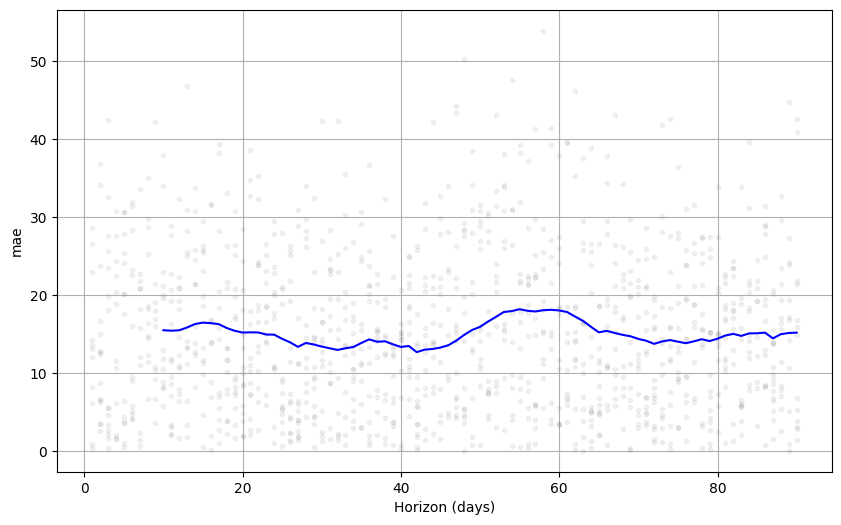

In [61]:
plot_cross_validation_metric(df_cv, metric='mae');

In [62]:
import json

In [63]:
from prophet.serialize import model_to_json

In [64]:
with open('modelo_O3_prophet.json', 'w') as file_out:
    json.dump(model_to_json(modelo_final), file_out)